# 3 · Minería de datos: encontrar patrones
**Torre del Caribe** · Universidad Nacional Rosario Castellanos · Licenciatura en Ciencia de Datos para Negocios, 5.º
semestre 2026-2 · Equipo 2

| | |
|---|---|
| **Materia (UCA)** | Minería de Datos |
| **Profesor** | Luis Becerril Espinosa |
| **Criterio de la rúbrica** | 3. Minería de datos (12 %) |
| **Equipo** | Brandon Uriel García Sánchez · Maribel Mondragón Mercado · Jesús Ramírez Isidro · Enrique González Ortega |

Antes de predecir (notebook 4) hay que entender los datos: **dónde** hay presión turística, **a quién se
parece** el norte de Quintana Roo, **cuándo** sube y baja cada lugar en el año, **qué semanas** tienen un clima fuera de
lo normal y **qué molesta** a los turistas de los destinos llenos. Cada respuesta es un patrón que la campaña usa.

| Parte | Qué respondemos |
|---|---|
| 1. Índice de presión turística | ¿Dónde hay presión y dónde hay espacio? |
| 2. Agrupamiento (Ward) | ¿A qué destinos del país se parece el norte de Quintana Roo? |
| 3. La forma del año | ¿En qué meses sube y baja cada lugar? ¿El sur se mueve con el norte? |
| 4. Clima raro (Isolation Forest) | ¿Qué semanas tienen un clima fuera de lo normal? |
| 5. Minería de texto | ¿Qué hace que una reseña sea mala o de 5 estrellas? |
| 6. Clasificación por léxico | ¿Qué es cada negocio del DENUE y cuándo conviene ir? |
| 7. Resumen de hiperparámetros | Cada valor que elegimos, por qué y qué descartamos |

**Cómo leer este notebook.** Antes de cada celda de código explicamos qué hacemos y por qué; dentro del código, cada
renglón lleva su comentario. Al terminar cada paso comparamos nuestro resultado con el que guardó el proyecto (función
`coincide`): si una cifra no coincidiera, el notebook se detendría ahí. El documento técnico del equipo
(*Torre_del_Caribe.pdf*) tiene las fórmulas con su ejemplo resuelto a mano.

**Cómo correrlo.** Python 3.11 con `pip install -r requirements.txt` desde la carpeta de la entrega; abrir en Jupyter o
VS Code y elegir *Ejecutar todo*. Ya viene ejecutado, así que también se puede leer sin correrlo.

In [1]:
%matplotlib inline
# Preparación. Buscamos la carpeta de la entrega (la que tiene datos/silver), cargamos las librerías,
# definimos el estilo de las gráficas y la función que compara nuestras cifras con las del proyecto.
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

warnings.filterwarnings("ignore")                        # avisos de versiones de librerías que no cambian resultados
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos" / "silver").is_dir())
SILVER, GOLD = RAIZ / "datos" / "silver", RAIZ / "datos" / "gold"   # datos limpios y resultados del proyecto
FIGURAS = Path.cwd() / "figuras"                          # aquí guardamos cada gráfica como PNG
FIGURAS.mkdir(exist_ok=True)

# Colores institucionales de la UNRC (guinda y dorado) y una paleta para varias series.
GUINDA, DORADO, GRIS = "#9F2241", "#BC955C", "#3A3A3A"
PALETA = ["#9F2241", "#BC955C", "#565393", "#58A65D", "#8CAFDD", "#F26E50", "#465973"]
for f in (RAIZ / "herramientas" / "fuentes").glob("NotoSans-*.ttf"):
    font_manager.fontManager.addfont(str(f))          # la letra Noto Sans viene en la entrega
plt.rcParams.update({"font.family": "Noto Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlecolor": GUINDA, "axes.titlesize": 12,
                     "text.color": GRIS, "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
                     "figure.facecolor": "white", "savefig.dpi": 160, "savefig.bbox": "tight"})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)


def coincide(nombre, nuestro, proyecto, tolerancia=1e-6):
    """Compara un resultado de este notebook con el que guardó el proyecto. Si no coincide, se detiene."""
    a = np.asarray(nuestro, dtype=float).ravel()
    b = np.asarray(proyecto, dtype=float).ravel()
    assert a.shape == b.shape, f"{nombre}: tamaños distintos {a.shape} y {b.shape}"
    dif = float(np.nanmax(np.abs(a - b))) if len(a) else 0.0
    print(f"{'✓' if dif <= tolerancia else '✗'} {nombre}: coincide con el proyecto (diferencia máxima {dif:.2g})")
    assert dif <= tolerancia, f"{nombre} no coincide con el proyecto"


def guardar(fig, nombre):
    """Guarda la gráfica en figuras/ con un nombre claro."""
    fig.savefig(FIGURAS / f"{nombre}.png")


print("Carpeta de la entrega:", RAIZ)

Carpeta de la entrega: C:\Users\Uriel\Desktop\PP 5to semestre CASCO SANTO TOMAS\Entregable


## 1. El índice de presión turística (IPT)
### La idea
No existe una sola medida oficial de "qué tan lleno está un lugar". Hay varias, cada una para algunos lugares: llegadas
en Tren Maya, cruceristas, visitantes a zonas arqueológicas, ocupación hotelera. El IPT las junta en un número de 0 a 1.

1. **Por habitante.** Las llegadas se dividen entre la población (por mil habitantes): 1,000 visitantes pesan más en
   Nicolás Bravo que en Chetumal. Además, *llegadas por cuarto* mide la presión contra la capacidad de hospedaje.
2. **A la misma escala.** Cada medida se lleva a 0–1 con mín–máx, usando el mínimo y el máximo de **todos** los lugares y
   meses juntos: $z_k = (x_k - \min x_k)/(\max x_k - \min x_k)$.
3. **Promedio con pesos iguales** de las medidas que el lugar tiene ese mes: $\text{IPT} = \sum_k w_k z_k / \sum_k w_k$.

Partimos del panel mensual (una fila por lugar y mes, armado en el notebook 1 con SITUR-Q, INAH y DataTur).

In [2]:
panel = pd.read_parquet(GOLD / "radar_panel_mensual.parquet")
print(f"{panel.lugar.nunique()} lugares × {panel.periodo.nunique()} meses ({panel.periodo.min():%Y-%m} a {panel.periodo.max():%Y-%m})")

LLEGADAS = ["llegadas_tren", "cruceristas", "cruces_belice", "visitantes_inah"]
c = panel[["lugar", "es_de_los_5", "periodo"]].copy()
for v in LLEGADAS:
    c[f"{v}_x1000hab"] = panel[v] / panel.poblacion * 1000                    # llegadas por mil habitantes
llegadas = panel[["llegadas_tren", "cruceristas"]].astype(float).sum(axis=1, min_count=1)   # nulo si no hay ninguna
c["llegadas_x_cuarto"] = llegadas / panel.cuartos.astype(float)               # presión contra la capacidad de hospedaje
c["ocupacion_pct"] = panel.ocupacion_pct

CANDIDATOS = [f"{v}_x1000hab" for v in LLEGADAS] + ["llegadas_x_cuarto", "ocupacion_pct"]
comps = [k for k in CANDIDATOS if c.loc[c[k].notna(), "lugar"].nunique() >= 2]  # una medida de un solo lugar no se compara
print("Entran al índice:", comps, "· fuera:", sorted(set(CANDIDATOS) - set(comps)))
c.groupby("lugar")[comps].count()

15 lugares × 55 meses (2022-01 a 2026-07)
Entran al índice: ['llegadas_tren_x1000hab', 'cruceristas_x1000hab', 'visitantes_inah_x1000hab', 'llegadas_x_cuarto', 'ocupacion_pct'] · fuera: ['cruces_belice_x1000hab']


,llegadas_tren_x1000hab,cruceristas_x1000hab,visitantes_inah_x1000hab,llegadas_x_cuarto,ocupacion_pct
lugar,,,,,
Bacalar,20,0,55,20,12
Bahía Calderitas–Oxtankah,0,0,55,0,0
Cancún,31,0,55,31,55
Chetumal,20,0,0,20,36
Costa Mujeres,0,0,0,0,36
Cozumel,0,55,55,55,55
Holbox,24,0,0,24,12
Isla Mujeres,0,0,0,0,55
Laguna Milagros–Xul-Ha,0,0,0,0,0


**Por qué sale *cruces desde Belice*.** Solo Chetumal la tiene. Con un solo lugar, el mín–máx lo compara
contra sí mismo: Chetumal quedaba en 0.44 en 2025, arriba de Cancún (0.28), solo porque la mediana de sus cruces cae en
0.74 de su propia escala. La regla es que una medida entra si la tienen al menos 2 lugares. Belice sigue en el panel y
en el pronóstico; solo no entra al índice.

In [3]:
z = c[["lugar", "es_de_los_5", "periodo"]].copy()
for k in comps:
    x = c[k].astype(float)
    z[f"z_{k}"] = (x - x.min()) / (x.max() - x.min())                         # escala 0–1 común a todos

def ipt(z, pesos=None):
    """Promedio ponderado de las medidas que el lugar tiene ese mes (las que faltan no cuentan, no se rellenan)."""
    pesos = pesos or {k: 1.0 for k in comps}
    Z = z[[f"z_{k}" for k in comps]].to_numpy(dtype=float)
    W = np.array([pesos[k] for k in comps])
    hay = ~np.isnan(Z)
    suma_w = (hay * W).sum(axis=1)
    with np.errstate(invalid="ignore"):
        return np.where(suma_w > 0, np.nansum(np.nan_to_num(Z) * W, axis=1) / suma_w, np.nan)

def estados(valores, cortes=(0.50, 0.90)):
    u50, u90 = np.nanquantile(valores, cortes)                                # percentiles comunes a todo el estado
    return np.select([np.isnan(valores), valores < u50, valores <= u90], ["sin dato oficial", "tranquilo", "concurrido"],
                     default="saturado"), (u50, u90)

z["ipt"] = ipt(z)
z["estado"], cortes = estados(z.ipt.to_numpy())
proyecto = pd.read_parquet(GOLD / "radar_estado.parquet")
coincide("IPT de cada lugar y mes", z.ipt, proyecto.ipt)
print(f"Cortes: p50 = {cortes[0]:.3f} · p90 = {cortes[1]:.3f}")
z[z.estado != "sin dato oficial"].estado.value_counts()

✓ IPT de cada lugar y mes: coincide con el proyecto (diferencia máxima 0)
Cortes: p50 = 0.258 · p90 = 0.766


estado
tranquilo     351
concurrido    281
saturado       71
Name: count, dtype: int64

### Tres decisiones del índice, y por qué

| Decisión | Elegimos | Por qué | Qué descartamos |
|---|---|---|---|
| Pesos | **Iguales**, con sensibilidad ±50 % | No hay evidencia para decir que una medida importa más que otra; con pesos iguales cualquiera repite el cálculo | **Componentes principales (PCA)**: los pesos salen de la varianza, no de la presión, y cambian cada vez que llegan datos |
| Estados | **Percentiles 50 y 90 comunes** a todo el estado | "Saturado" quiere decir lo mismo en Tulum que en Chetumal: el 10 % más alto de todo Quintana Roo | **Terciles de cada lugar** (cada uno tendría su propio "lleno"); **k-means** (los cortes se mueven con cada corrida) |
| Escala | **Mín–máx** | Se explica en un renglón y conserva las distancias | Percentil común (borra las distancias); mín–máx sobre logaritmos |

**Un riesgo que declaramos.** Con colas largas, la mediana de visitantes INAH por mil habitantes queda en 0.02 de su
escala y la de ocupación en 0.70: un lugar puede salir más alto solo por tener la medida de ocupación. Por eso medimos la
**sensibilidad**: movemos el peso de cada medida a la mitad y al 150 % y contamos cuántos lugar-mes cambian de estado.

In [4]:
con_dato = z.estado != "sin dato oficial"
filas = []
for k in comps:
    for factor in (0.5, 1.5):
        nuevo, _ = estados(ipt(z, {j: (factor if j == k else 1.0) for j in comps}))
        cambia = (nuevo != z.estado) & con_dato
        filas.append({"medida": k, "peso": factor, "cambian (%)": round(100 * cambia.sum() / con_dato.sum(), 1),
                      "cambian en los 5 lugares": int((cambia & z.es_de_los_5).sum())})
sens = pd.DataFrame(filas)
sens.pivot(index="medida", columns="peso", values="cambian (%)")

peso,0.5,1.5
medida,,
cruceristas_x1000hab,2.0,0.6
llegadas_tren_x1000hab,3.1,1.7
llegadas_x_cuarto,3.1,2.0
ocupacion_pct,5.7,6.0
visitantes_inah_x1000hab,3.1,2.3


Moviendo el peso de cualquier medida a la mitad o al 150 %, cambia de estado entre el 0.6 % y el 6 % de los
lugar-mes; la que más mueve es la ocupación (5.7 y 6.0 %). El resultado del índice no depende de un peso elegido a mano.

### El índice comparable (el que usa el clasificador)
En 2025 SITUR-Q dejó de publicar la ocupación del sur. Si el índice se calculara con lo que hubiera cada mes, Chetumal
"bajaría" de 0.54 a 0.05 solo por perder una medida, no porque llegara menos gente. Para el aprendizaje de máquina cada
lugar usa **solo las medidas que tiene hoy, y solo los meses en que las tiene todas**. Así un cambio de estado siempre
es un cambio real.

✓ índice comparable: coincide con el proyecto (diferencia máxima 0)


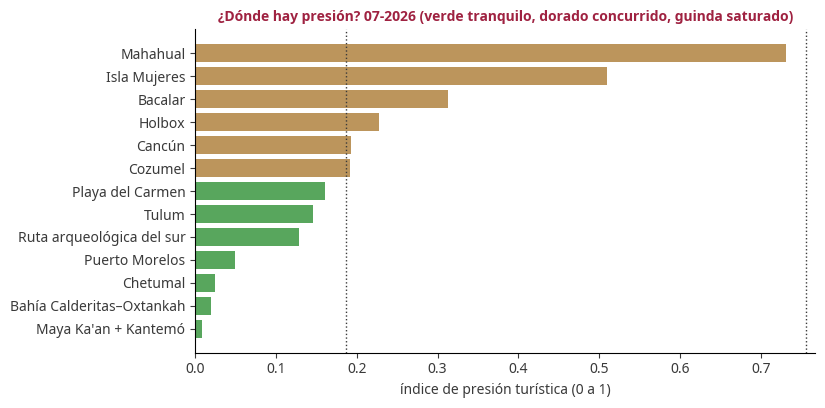

In [5]:
base = c.merge(z, on=["lugar", "es_de_los_5", "periodo"])
filas = []
for lugar, g in base.groupby("lugar"):
    g = g.sort_values("periodo")
    con = g[g.ipt.notna()]
    if con.empty:
        continue
    actuales = [k for k in comps if pd.notna(con.iloc[-1][f"z_{k}"])]          # las medidas de su último mes con dato
    Zl = g[[f"z_{k}" for k in actuales]]
    completo = Zl.notna().all(axis=1)                                         # solo meses con todas esas medidas
    filas.append(g.assign(ipt_comparable=Zl.mean(axis=1).where(completo), medidas=", ".join(actuales))
                 [["lugar", "es_de_los_5", "periodo", "ipt_comparable", "medidas"]])
tc = pd.concat(filas, ignore_index=True)
tc["estado"], cortes_c = estados(tc.ipt_comparable.to_numpy())
coincide("índice comparable", tc.ipt_comparable, pd.read_parquet(GOLD / "radar_indice_comparable.parquet").ipt_comparable)

ultimo = tc.dropna(subset=["ipt_comparable"]).periodo.max()
x = tc[tc.periodo == ultimo].dropna(subset=["ipt_comparable"]).sort_values("ipt_comparable")
colores = {"tranquilo": PALETA[3], "concurrido": DORADO, "saturado": GUINDA}
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(x.lugar, x.ipt_comparable, color=x.estado.map(colores))
for u in cortes_c:
    ax.axvline(u, color=GRIS, ls=":", lw=1)
ax.set_xlabel("índice de presión turística (0 a 1)")
ax.set_title(f"¿Dónde hay presión? {ultimo:%m-%Y} (verde tranquilo, dorado concurrido, guinda saturado)", fontsize=10)
guardar(fig, "3_ipt_ultimo_mes")

## 2. Agrupamiento: ¿a qué se parece el norte?
Los 5 lugares del sur no están en DataTur, pero el norte sí, junto con los demás centros turísticos del país (55 con los 55 meses completos). Agrupamos los
centros por su **perfil de 12 meses**: la ocupación promedio de cada mes del año (cuartos ocupados ÷ disponibles de ese
mes en 2022–2026). Así el grupo depende de qué tan lleno está un centro **y** de cuándo.

**Ward** es un agrupamiento jerárquico: empieza con cada centro solo y en cada paso une los dos grupos que **menos
aumentan la varianza dentro de los grupos**. El número de grupos lo elegimos con el **coeficiente de silueta** (de −1 a
1: qué tan cerca está cada centro de su grupo comparado con el grupo vecino).

In [6]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

o = pd.read_parquet(SILVER / "datatur_ocupacion", columns=["centro", "es_qroo", "frecuencia", "tipo_fila", "periodo",
                                                           "cuartos_ocupados", "cuartos_disponibles"])
o = o[(o.frecuencia == "mensual") & (o.tipo_fila == "centro")].copy()      # centros, no agregados como "Total"
o["periodo"] = pd.to_datetime(o.periodo.astype(str))
total = o.periodo.nunique()
completos = [cc for cc, g in o.groupby("centro") if g.periodo.nunique() == total and g.cuartos_ocupados.notna().all()
             and (g.cuartos_disponibles.fillna(0) > 0).all()]              # sin meses vacíos (no se rellenan)
o = o[o.centro.isin(completos)].assign(mes=lambda x: x.periodo.dt.month)
s = o.groupby(["centro", "mes"])[["cuartos_ocupados", "cuartos_disponibles"]].sum()
perfil = (100 * s.cuartos_ocupados / s.cuartos_disponibles).unstack("mes")   # ocupación de cada mes del año
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
perfil.columns = MESES

Z = linkage(perfil.to_numpy(), method="ward")
siluetas = {k: silhouette_score(perfil, fcluster(Z, k, criterion="maxclust")) for k in range(2, 9)}
k = max(siluetas, key=siluetas.get)
grupo = pd.Series(fcluster(Z, k, criterion="maxclust"), index=perfil.index)
coincide("grupo de cada centro", grupo, pd.read_parquet(GOLD / "radar_clusters_centros.parquet").set_index("centro").grupo.reindex(perfil.index))
print(f"{len(perfil)} centros con {total} meses completos · silueta por k:", {kk: round(v, 3) for kk, v in siluetas.items()}, "→ k =", k)

✓ grupo de cada centro: coincide con el proyecto (diferencia máxima 0)
55 centros con 55 meses completos · silueta por k: {2: 0.45, 3: 0.38, 4: 0.365, 5: 0.3, 6: 0.283, 7: 0.317, 8: 0.306} → k = 2


       nivel  amplitud  centros
grupo                          
1       64.5      19.9       23
2       41.1      17.6       32

Quintana Roo: {'Akumal': {'grupo': 1, 'nivel': 74.6}, 'Cancun': {'grupo': 1, 'nivel': 74.0}, 'Cozumel': {'grupo': 2, 'nivel': 52.7}, 'Isla Mujeres': {'grupo': 2, 'nivel': 51.6}, 'Playa Del Carmen': {'grupo': 1, 'nivel': 68.7}, 'Playacar': {'grupo': 1, 'nivel': 83.2}, 'Riviera Maya': {'grupo': 1, 'nivel': 72.9}}


Coincidencia Ward contra k-means (índice de Rand ajustado, 1 = idénticos): 0.49


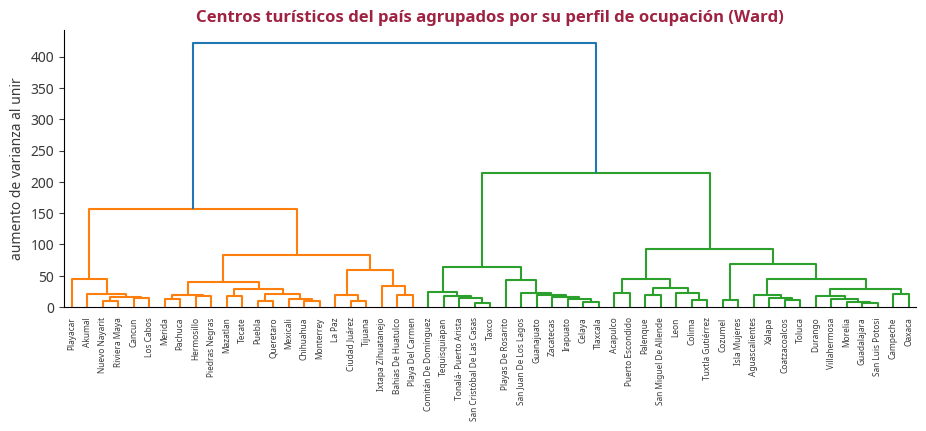

In [7]:
qroo = o.drop_duplicates("centro").set_index("centro").es_qroo
resumen = perfil.assign(grupo=grupo, nivel=perfil.mean(axis=1), amplitud=perfil.max(axis=1) - perfil.min(axis=1))
print(resumen.groupby("grupo")[["nivel", "amplitud"]].mean().round(1).assign(centros=resumen.groupby("grupo").size()).to_string())
print("\nQuintana Roo:", resumen[qroo.reindex(perfil.index).astype(bool)][["grupo", "nivel"]].round(1).to_dict("index"))

fig, ax = plt.subplots(figsize=(11, 3.6))
dendrogram(Z, labels=perfil.index.tolist(), leaf_font_size=6, color_threshold=Z[-k + 1, 2], ax=ax)
ax.set_ylabel("aumento de varianza al unir"); ax.set_title("Centros turísticos del país agrupados por su perfil de ocupación (Ward)")
guardar(fig, "3_dendrograma_ward")

# Segunda opinión: k-means con el mismo k. Si coincide, los grupos no son un capricho del método.
km = KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(perfil)
print(f"Coincidencia Ward contra k-means (índice de Rand ajustado, 1 = idénticos): {adjusted_rand_score(grupo, km):.2f}")

**Lectura.** La silueta más alta da 2 grupos: los centros de playa más llenos (con Cancún, la Riviera Maya,
Playa del Carmen, Playacar y Akumal) y el resto del país, donde quedan Cozumel e Isla Mujeres. El norte de Quintana Roo
está en el grupo de **presión más alta del país**: es el problema que la campaña quiere aliviar.

**Por qué Ward y no k-means.** k-means pide fijar el número de grupos antes y su resultado depende del punto de
arranque; Ward da el árbol completo (dendrograma) y se elige el corte con la silueta. Aun así corrimos k-means como
segunda opinión: el índice de Rand ajustado da 0.49, una coincidencia media. Los 23 centros del grupo alto de Ward
quedan también en el grupo alto de k-means, que además suma 8 centros intermedios (entre ellos Cozumel e Isla Mujeres).
O sea: la frontera entre grupos depende del método, pero la conclusión que usamos no: **Cancún, la Riviera Maya, Playa
del Carmen, Playacar y Akumal están en el grupo de ocupación más alta con los dos métodos**. DBSCAN lo descartamos
porque con 55 centros y 12 dimensiones casi todos los puntos salen como "ruido".

**Por qué el perfil sin estandarizar.** Las 12 columnas están en la misma unidad (porcentaje de ocupación), así que no
hace falta estandarizarlas, y así el nivel (qué tan lleno) cuenta igual que la forma (cuándo).

## 3. La forma del año (estacionalidad)
Para cada serie medimos cuánto sube o baja cada mes contra el promedio de su año. Es una **descomposición clásica
multiplicativa** sobre años completos:

$$r_{a,m} = \frac{y_{a,m}}{\bar y_a}, \qquad S_m = \frac{\bar r_m}{\tfrac{1}{12}\sum_k \bar r_k}$$

**Multiplicativa** porque la temporada crece con el nivel: Kohunlich reabrió a la mitad de su nivel de 2019; "+2,000
visitantes en marzo" de 2019 no aplica en 2025, "+30 %" sí. La **fuerza de la temporada** (Wang, Smith y Hyndman, 2006)
dice qué tanto de la variación explica el mes: $F = \max(0, 1 - \text{Var}(e)/\text{Var}(s+e))$, en logaritmos.

✓ forma del año: coincide con el proyecto (diferencia máxima 0)
✓ fuerza de la temporada: coincide con el proyecto (diferencia máxima 0)
Fuerza de la temporada: {'Bahía Calderitas–Oxtankah': 0.68, 'Cancún (referencia)': 0.71, 'Chetumal': 0.65, 'Riviera Maya (referencia)': 0.73, 'Ruta arqueológica del sur': 0.79}
¿Se mueve con Cancún? (correlación de las formas): {'Bahía Calderitas–Oxtankah': 0.72, 'Chetumal': 0.26, 'Ruta arqueológica del sur': 0.83}


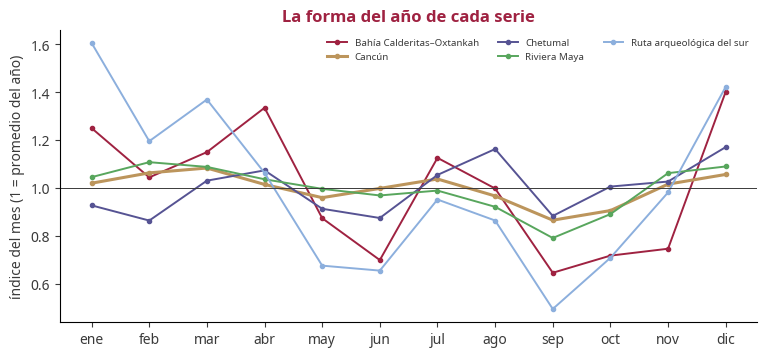

In [8]:
series = pd.read_parquet(GOLD / "pronostico_series.parquet")

def razones(s):
    n = s[s.entrena_flag].groupby(s.periodo.dt.year).size()
    anios = n[n == 12].index                                                  # solo años con los 12 meses útiles
    x = s[s.periodo.dt.year.isin(anios)].copy()
    x["anio"], x["mes"] = x.periodo.dt.year, x.periodo.dt.month
    x["razon"] = x.valor / x.groupby("anio").valor.transform("mean")          # el mes ÷ el promedio de su año
    return x.pivot(index="anio", columns="mes", values="razon")

filas, fuerza = [], {}
for serie, s in series.groupby("serie"):
    r = razones(s)
    i = r.mean(axis=0); i = i / i.mean()                                      # índice de cada mes, promedio 1
    sl = np.log(i.reindex(r.columns).to_numpy())[None, :].repeat(len(r), axis=0)
    e = np.log(r.to_numpy()) - sl                                             # lo que el mes no explica
    fuerza[serie] = max(0.0, 1 - np.var(e) / np.var(sl + e))
    filas += [{"serie": serie, "lugar": s.lugar.iloc[0], "mes": m, "indice": i[m]} for m in range(1, 13)]
forma = pd.DataFrame(filas)
coincide("forma del año", forma.indice.round(4), pd.read_parquet(GOLD / "pronostico_forma_anio.parquet").indice)
coincide("fuerza de la temporada", pd.Series(fuerza).round(3),
         pd.read_parquet(GOLD / "pronostico_fuerza_estacional.parquet").set_index("serie").fuerza_estacional.reindex(list(fuerza)))

ancho = forma.pivot(index="mes", columns="lugar", values="indice")
fig, ax = plt.subplots(figsize=(9, 3.8))
for lugar, color in zip(ancho.columns, PALETA):
    ax.plot(MESES, ancho[lugar], marker="o", ms=3, color=color, label=lugar, lw=2.2 if "Cancún" in lugar else 1.4)
ax.axhline(1, color=GRIS, lw=0.7); ax.set_ylabel("índice del mes (1 = promedio del año)")
ax.legend(frameon=False, fontsize=7, ncol=3); ax.set_title("La forma del año de cada serie")
guardar(fig, "3_forma_del_anio")
acompana = ancho.drop(columns=["Cancún", "Riviera Maya"]).apply(lambda col: np.corrcoef(np.log(col), np.log(ancho["Cancún"]))[0, 1])
print("Fuerza de la temporada:", {k.split(" · ")[0]: round(v, 2) for k, v in fuerza.items()})
print("¿Se mueve con Cancún? (correlación de las formas):", acompana.round(2).to_dict())

**Lectura.** La temporada es fuerte en todas las series (0.66 a 0.79). La Ruta recibe 61 % más en enero
que en un mes promedio y la mitad en septiembre. La Ruta y la Bahía **se mueven con Cancún** (correlación 0.83 y 0.72):
cuando el norte se llena, el sur también sube, y por eso el turista que ya está en el norte es el público natural de la
campaña. Los cruces desde Belice **no** (0.26): tienen su propio calendario (pico en diciembre).

**Por qué no STL.** STL (descomposición con Loess) es más flexible, pero necesita una serie **continua**, y las nuestras
tienen huecos de cierre y pandemia. Solo podría usar el tramo continuo más largo (unos 50 meses) y tiraría los años
posteriores. La usamos como **segunda opinión** sobre ese tramo: la correlación entre su forma y la nuestra es de 0.85 a
0.97 (tabla `pronostico_fuerza_estacional`).

## 4. Clima raro con Isolation Forest
### La pregunta
La Torre en vivo (notebook 6) pausa los anuncios del sur si la semana trae un clima fuera de lo normal. Pero, ¿qué es
"fuera de lo normal"? Un aguacero de 80 mm es normal en septiembre y raro en marzo. No quisimos fijar ese umbral a mano
para cada variable: que lo aprenda un modelo a partir de años de clima real.

### Los datos de cada semana
Del clima hora por hora (ERA5) de Chetumal y Kohunlich armamos una fila por semana completa: lluvia total, lluvia del peor
día, viento máximo, temperatura máxima y la **época del año** como seno y coseno (para que un aguacero de septiembre no
salga raro solo por ser septiembre).

In [9]:
from sklearn.ensemble import IsolationForest

ch = pd.read_parquet(SILVER / "clima_horario", columns=["punto", "fecha_hora_local", "temp_c", "lluvia_mm", "viento_kmh"])
ch = ch[ch.punto.isin(["chetumal", "kohunlich"])]
ch["dia"] = ch.fecha_hora_local.dt.normalize()
dd = ch.groupby(["punto", "dia"]).agg(lluvia=("lluvia_mm", "sum"), viento=("viento_kmh", "max"), temp=("temp_c", "max")).reset_index()
dd["semana"] = dd.dia - pd.to_timedelta(dd.dia.dt.weekday, unit="D")                # el lunes de cada semana
sem = dd.groupby(["punto", "semana"]).agg(lluvia_mm=("lluvia", "sum"), lluvia_max_dia_mm=("lluvia", "max"),
                                          viento_max_kmh=("viento", "max"), temp_max_c=("temp", "max"),
                                          dias=("dia", "nunique")).reset_index()
sem = sem[sem.dias == 7].copy()                                                      # solo semanas completas
ang = 2 * np.pi * sem.semana.dt.isocalendar().week.astype(float) / 52.18
sem["epoca_sin"], sem["epoca_cos"] = np.sin(ang), np.cos(ang)
VARIABLES = ["lluvia_mm", "lluvia_max_dia_mm", "viento_max_kmh", "temp_max_c", "epoca_sin", "epoca_cos"]
print(f"{len(sem)} semanas · {sem.semana.min():%Y-%m-%d} a {sem.semana.max():%Y-%m-%d}")
sem.groupby("punto")[VARIABLES[:4]].describe().T.round(1)

806 semanas · 2019-01-07 a 2026-09-21


punto                    chetumal  kohunlich
lluvia_mm         count     403.0      403.0
                  mean       25.0       23.8
                  std        28.3       30.2
                  min         0.1        0.1
                  25%         6.1        5.9
                  50%        14.2       13.3
                  75%        34.2       31.4
                  max       182.3      373.4
lluvia_max_dia_mm count     403.0      403.0
                  mean       10.7       10.2
                  std        11.9       12.3
                  min         0.1        0.1
                  25%         2.6        2.4
                  50%         6.0        5.8
                  75%        15.0       13.8
                  max        71.6      113.4
viento_max_kmh    count     403.0      403.0
                  mean       21.8       18.6
                  std         4.0        3.0
                  min        11.3       11.1
                  25%        18.7       16.6
                  50%        22.0       18.9
                  75%        24.6       20.7
                  max        32.7       27.7
temp_max_c        count     403.0      403.0
                  mean       31.1       32.9
                  std         1.7        2.3
                  min        27.0       27.7
                  25%        29.8       31.2
                  50%        31.3       33.0
                  75%        32.4       34.6
                  max        37.1       39.2

### Cómo funciona Isolation Forest
Un **árbol de aislamiento** parte los datos con cortes al azar (elige una variable al azar y un valor al azar entre su
mínimo y su máximo) hasta dejar cada punto solo. Un punto raro queda solo **muy rápido**, en pocos cortes, porque está
lejos de los demás; uno normal necesita muchos. Con muchos árboles, el puntaje de anomalía es:

$$s(x) = 2^{-E[h(x)]/c(n)}$$

donde $E[h(x)]$ es el número promedio de cortes para aislar a $x$ y $c(n)$ es el promedio esperado para $n$ puntos. Cerca
de 1 es muy raro; cerca de 0.5 o menos, normal.

**Cómo lo entrenamos sin ver el futuro.** Un bosque por punto y por año: para calificar las semanas de 2024, el bosque
aprende con todas las semanas de 2019 a 2023 (ventana creciente). 2019–2021 solo sirven para aprender.

**El corte.** Una semana es rara si su puntaje pasa el **percentil 95** de los puntajes de las semanas de entrenamiento:
más rara que 19 de cada 20 semanas ya conocidas.

In [10]:
CORTE_RARO = 0.95
partes = []
for punto, x in sem.groupby("punto"):
    x = x.copy(); x["anio"] = x.semana.dt.year
    x["puntaje"], x["corte"], x["raro"], x["raro_auto"] = np.nan, np.nan, None, None
    for anio in range(2022, int(x.anio.max()) + 1):
        entrena = x[(x.semana >= "2019-01-01") & (x.semana < f"{anio}-01-01")]       # todo lo anterior a ese año
        bosque = IsolationForest(n_estimators=300, contamination="auto", random_state=0).fit(entrena[VARIABLES])
        corte = np.quantile(-bosque.score_samples(entrena[VARIABLES]), CORTE_RARO)   # percentil 95 de lo ya conocido
        esta = x.anio == anio
        x.loc[esta, "puntaje"] = -bosque.score_samples(x.loc[esta, VARIABLES])       # más alto = más raro
        x.loc[esta, "corte"] = corte
        x.loc[esta, "raro"] = x.loc[esta, "puntaje"] > corte
        x.loc[esta, "raro_auto"] = bosque.predict(x.loc[esta, VARIABLES]) == -1       # el corte "auto" del artículo original
    partes.append(x)
anom = pd.concat(partes, ignore_index=True)

senales = pd.read_parquet(GOLD / "envivo_senales.parquet")
for punto in ("chetumal", "kohunlich"):
    a = anom[anom.punto == punto].set_index("semana").puntaje.reindex(senales.semana)
    coincide(f"puntaje de anomalía, {punto}", a, senales[f"{punto}_puntaje_anomalia"])
cal = anom.dropna(subset=["puntaje"])
print(cal.groupby("punto").agg(semanas=("raro", "size"), raras_p95=("raro", "sum"), raras_auto=("raro_auto", "sum")))

✓ puntaje de anomalía, chetumal: coincide con el proyecto (diferencia máxima 0)
✓ puntaje de anomalía, kohunlich: coincide con el proyecto (diferencia máxima 0)
           semanas raras_p95 raras_auto
punto                                  
chetumal       247        21         88
kohunlich      247        17         49


**Por qué el percentil 95 y no el corte "auto".** El artículo original de Isolation Forest propone marcar
como raro lo que pase un puntaje fijo (0.5). Con eso, el bosque marca 88 de 247 semanas de Chetumal (36 %) y 49 de
Kohunlich (20 %) como raras: desde 2022 llueve más y hace más calor que en 2019–2021, y un corte fijo no distingue. Con el percentil 95 de lo
ya conocido, el número de semanas raras queda en lo que esperaríamos (alrededor de 1 de cada 20) y se ajusta solo al
crecer la ventana.

### ¿Encuentra lo que debe encontrar? Las semanas de tormenta
La prueba más dura: en 2022–2025 hubo 3 semanas con una tormenta a menos de 200 km de Chetumal (Lisa, Nadine y Sara).
El bosque **nunca supo** de las tormentas: solo vio lluvia, viento, calor y época. Si las marca como raras, aprendió algo
real.

In [11]:
tormenta = senales[senales.tormenta == True][["semana", "tormenta_nombre"]]
r = anom.pivot(index="semana", columns="punto", values="raro")
tormenta.assign(chetumal_raro=tormenta.semana.map(r.chetumal), kohunlich_raro=tormenta.semana.map(r.kohunlich))

,semana,tormenta_nombre,chetumal_raro,kohunlich_raro
43,2022-10-31,Lisa,True,True
145,2024-10-14,Nadine,True,True
149,2024-11-11,Sara,True,True


### Comparación con otros detectores
Para justificar el método, corremos tres alternativas con la **misma** ventana creciente y el **mismo** corte
(percentil 95 de lo conocido), y contamos cuántas de las 3 semanas de tormenta encuentra cada uno:

- **Regla de 3 desviaciones (z-score):** raro si alguna variable se aleja más de 3 desviaciones de su promedio. Es lo
  más simple, pero mira cada variable por separado y no sabe que 80 mm es normal en septiembre.
- **Local Outlier Factor (LOF):** compara la densidad de vecinos de cada semana con la de sus vecinos.
- **One-Class SVM:** traza una frontera alrededor de las semanas normales.

In [12]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.pipeline import make_pipeline

def detectar(fabrica):
    """Misma ventana creciente y mismo corte p95 para cualquier detector; devuelve las semanas raras por punto."""
    raras = {}
    for punto, x in sem.groupby("punto"):
        x = x.copy(); x["anio"] = x.semana.dt.year
        marcadas = []
        for anio in range(2022, int(x.anio.max()) + 1):
            entrena = x[(x.semana >= "2019-01-01") & (x.semana < f"{anio}-01-01")]
            prueba = x[x.anio == anio]
            puntaje_entrena, puntaje = fabrica(entrena[VARIABLES], prueba[VARIABLES])
            marcadas += list(prueba.semana[puntaje > np.quantile(puntaje_entrena, CORTE_RARO)])
        raras[punto] = set(marcadas)
    return raras

def z_score(e, p):
    m, s = e.iloc[:, :4].mean(), e.iloc[:, :4].std()
    return (np.abs((e.iloc[:, :4] - m) / s).max(axis=1).to_numpy(), np.abs((p.iloc[:, :4] - m) / s).max(axis=1).to_numpy())

def lof(e, p):
    m = make_pipeline(StandardScaler(), LocalOutlierFactor(n_neighbors=20, novelty=True)).fit(e)
    return -m.score_samples(e), -m.score_samples(p)

def ocsvm(e, p):
    m = make_pipeline(StandardScaler(), OneClassSVM(nu=0.05)).fit(e)
    return -m.score_samples(e), -m.score_samples(p)

def bosque(e, p):
    m = IsolationForest(n_estimators=300, random_state=0).fit(e)
    return -m.score_samples(e), -m.score_samples(p)

semanas_tormenta = set(tormenta.semana)
filas = []
for nombre, f in [("Isolation Forest (elegido)", bosque), ("Regla de 3 desviaciones", z_score),
                  ("Local Outlier Factor", lof), ("One-Class SVM", ocsvm)]:
    raras = detectar(f)
    for punto, rr in raras.items():
        filas.append({"detector": nombre, "punto": punto, "semanas raras": len(rr),
                      "tormentas encontradas (de 3)": len(rr & semanas_tormenta)})
pd.DataFrame(filas).pivot(index="detector", columns="punto", values=["semanas raras", "tormentas encontradas (de 3)"])

semanas raras           tormentas encontradas (de 3)          
punto                           chetumal kohunlich                     chetumal kohunlich
detector                                                                                 
Isolation Forest (elegido)            21        17                            3         3
Local Outlier Factor                  26        30                            3         3
One-Class SVM                         71        33                            3         3
Regla de 3 desviaciones               23        20                            3         3

**Por qué Isolation Forest.** (1) Mira las seis variables **juntas**: una semana con lluvia alta, viento
alto y época de secas es rara aunque ninguna variable sola rompa un récord. (2) No supone que el clima siga una campana
normal (la lluvia no lo hace: muchos días en cero y pocos enormes). (3) No necesita estandarizar ni elegir una distancia,
a diferencia de LOF y One-Class SVM, cuyo resultado cambia con esas decisiones. (4) Es rápido y se explica con la idea de
"cuántos cortes hacen falta para aislar a una semana".

**Lo que dice la tabla.** Los cuatro detectores encuentran las 3 tormentas, así que la diferencia está en las **falsas
alarmas**: cada semana rara pausa los anuncios del sur. Isolation Forest es el que menos semanas marca (21 en Chetumal y
17 en Kohunlich, de 247); One-Class SVM marca 71 en Chetumal, casi una de cada tres. Con el bosque la campaña se pausa
cuando hace falta y no a cada rato.

| Hiperparámetro | Valor | Por qué | Qué descartamos |
|---|---|---|---|
| Árboles | **300** | El puntaje se estabiliza; con 100 cambia un poco entre semillas | 100 (el valor de scikit-learn) |
| Corte | **Percentil 95** de lo ya conocido | Raro = más raro que 19 de cada 20 semanas vistas | Corte "auto" del artículo (marcaba 36 % de las semanas de Chetumal) |
| Entrenamiento | **Ventana creciente** desde 2019 | Nunca usa el futuro; aprende cada año con más datos | Entrenar con todo (vería el futuro) |
| Variables | Lluvia, lluvia del peor día, viento, calor, época | Lo que cambia los planes de un viajero | Humedad o presión (no cambian la decisión) |
| Semilla | 0 | Para que se pueda repetir | — |

## 5. Minería de texto: qué molesta en los destinos llenos
Usamos el corpus **Rest-Mex 2025**: 85,987 reseñas de Quintana Roo, de Tulum, Isla Mujeres y Bacalar. Ninguna es de los 5
lugares del sur (Rest-Mex no los cubre); el texto nos dice **qué molesta en los destinos llenos y qué valora el turista**,
y eso sostiene la promesa de la campaña. No es una opinión del sur, y así se presenta.

### 5.1 Temas con un léxico
Definimos cada tema con raíces de palabra, a la vista (por ejemplo, *multitudes*: "gente", "lleno", "fila",
"saturad"...). Una reseña toca un tema si alguna raíz aparece al inicio de una palabra. Luego medimos el **riesgo
relativo**: qué tanto más seguido es mala (1 o 2 estrellas) una reseña que toca el tema, contra todas.

$$RR_{\text{tema}} = \frac{P(\text{mala} \mid \text{toca el tema})}{P(\text{mala})}$$

**Por qué léxico y no LDA o NMF (modelos de temas).** Un tema de LDA es una lista de palabras que hay que adivinar qué
significa; un tema del léxico lo definimos nosotros y se defiende palabra por palabra. Para una campaña que tiene que
explicar cada promesa, preferimos lo explicable.

In [13]:
import re
ASPECTOS = {
    "multitudes": ["gente", "lleno", "llena", "multitud", "abarrot", "saturad", "concurrid", "masific", "aglomer",
                   "fila", "filas", "esperar", "espera ", "demasiados turistas", "muchos turistas"],
    "precio": ["caro", "cara", "caros", "caras", "costos", "precio", "cobr", "tarifa", "propina", "barat", "dinero"],
    "limpieza": ["sucio", "sucia", "sucied", "basura", "limpi", "sargazo", "olor", "apest", "mugr"],
    "ruido": ["ruido", "ruidos", "escándalo", "música alta", "fiesta"],
    "calma": ["tranquil", "paz", "relaj", "silencio", "calma", "sereno", "serena"],
    "naturaleza": ["naturalez", "selva", "laguna", "cenote", "manglar", "aves", "pájaro", "agua cristalina", "colores"],
    "cultura": ["ruina", "pirámide", "piramide", "maya", "historia", "arqueol", "cultura", "templo"],
    "comida": ["comida", "platillo", "delicios", "sabor", "mariscos", "tacos", "ceviche", "pescado"],
    "servicio": ["personal", "servicio", "atención", "amable", "mesero", "anfitri", "recepción"]}

r = pd.read_parquet(SILVER / "restmex", filters=[("estado", "=", "Quintana Roo")], columns=["titulo", "resena", "calificacion", "pueblo"])
r["texto"] = (r.titulo.fillna("") + ". " + r.resena.fillna("")).str.lower()      # título y reseña, en minúsculas
for tema, raices in ASPECTOS.items():
    patron = r"\b(?:" + "|".join(re.escape(x.strip()) for x in raices) + ")"      # la raíz al inicio de una palabra
    r[tema] = r.texto.str.contains(patron, regex=True)
r["mala"], r["cinco"] = r.calificacion <= 2, r.calificacion == 5
print(f"{len(r):,} reseñas · malas: {r.mala.mean():.1%} · de 5 estrellas: {r.cinco.mean():.1%}")

tabla = pd.DataFrame({tema: {"menciona (%)": 100 * r[tema].mean(), "malas entre ellas (%)": 100 * r.mala[r[tema]].mean(),
                             "riesgo relativo": r.mala[r[tema]].mean() / r.mala.mean()} for tema in ASPECTOS}).T
proyecto = pd.read_parquet(GOLD / "campana_aspectos.parquet")
proyecto = proyecto[proyecto.pueblo == "Quintana Roo (3 pueblos)"].set_index("aspecto")
coincide("riesgo relativo por tema", tabla["riesgo relativo"], proyecto.riesgo_relativo.reindex(tabla.index))
tabla.sort_values("riesgo relativo", ascending=False).round(2)

85,987 reseñas · malas: 4.2% · de 5 estrellas: 69.9%
✓ riesgo relativo por tema: coincide con el proyecto (diferencia máxima 0)


,menciona (%),malas entre ellas (%),riesgo relativo
ruido,2.37,11.53,2.76
limpieza,11.07,7.92,1.89
precio,25.58,6.96,1.66
multitudes,17.95,6.35,1.52
servicio,44.24,4.95,1.18
comida,40.35,3.40,0.81
naturaleza,13.92,3.06,0.73
cultura,18.28,1.99,0.48
calma,12.29,1.72,0.41


**Lectura.** Las reseñas que hablan de **ruido** (2.8 veces), **limpieza** (1.9), **precio** (1.7) y
**multitudes** (1.5) son malas más seguido que el promedio; las que hablan de **calma** (0.41), **cultura** (0.48) y
**naturaleza** (0.73), mucho menos.
Lo que molesta en los destinos llenos es justo lo que el sur ofrece al revés: espacio, calma, selva y pirámides.

### 5.2 Reglas de asociación (Apriori)
Ahora combinaciones: ¿qué **pares o tríos** de temas llevan a una reseña mala o a una de 5 estrellas? Cada reseña es
una "canasta" con los temas que toca más su calificación. Apriori encuentra las combinaciones frecuentes y de ellas las
reglas *si {temas} → entonces {calificación}*, con:

- **soporte**: qué fracción de reseñas tiene todo junto;
- **confianza**: de las que tienen los temas, qué fracción tiene esa calificación;
- **lift**: confianza ÷ frecuencia de la calificación. Lift 2 = el doble de lo normal.

In [14]:
from mlxtend.frequent_patterns import apriori, association_rules

canasta = r[list(ASPECTOS)].copy()
canasta["reseña mala (1–2)"], canasta["reseña de 5"] = r.mala, r.cinco
frec = apriori(canasta.astype(bool), min_support=0.001, use_colnames=True, max_len=3)   # al menos 86 reseñas, hasta 3 cosas
reg = association_rules(frec, metric="lift", min_threshold=1.0)                          # solo reglas que suben la probabilidad
CAL = {"reseña mala (1–2)", "reseña de 5"}
reg = reg[reg.consequents.apply(lambda cc: len(cc) == 1 and next(iter(cc)) in CAL)
          & reg.antecedents.apply(lambda a: not (a & CAL))].copy()
reg["si"] = reg.antecedents.apply(lambda a: " + ".join(sorted(a)))
reg["entonces"] = reg.consequents.apply(lambda cc: next(iter(cc)))
reg = reg[["si", "entonces", "support", "confidence", "lift"]].rename(columns={"support": "soporte", "confidence": "confianza"})
reg = reg.sort_values(["entonces", "lift"], ascending=[True, False]).reset_index(drop=True)
coincide("reglas de asociación (lift)", reg.lift, pd.read_parquet(GOLD / "campana_reglas.parquet").lift)
reg.groupby("entonces").head(6).round(3)

✓ reglas de asociación (lift): coincide con el proyecto (diferencia máxima 0)


,si,entonces,soporte,confianza,lift
0,comida + servicio,reseña de 5,0.201,0.781,1.118
1,calma + naturaleza,reseña de 5,0.017,0.766,1.097
2,comida,reseña de 5,0.305,0.757,1.083
3,calma + comida,reseña de 5,0.036,0.755,1.081
4,calma + servicio,reseña de 5,0.046,0.750,1.074
5,servicio,reseña de 5,0.328,0.741,1.061
13,ruido + servicio,reseña mala (1–2),0.002,0.118,2.819
14,ruido,reseña mala (1–2),0.003,0.115,2.756
15,limpieza + multitudes,reseña mala (1–2),0.003,0.108,2.592
16,limpieza + precio,reseña mala (1–2),0.004,0.106,2.540


| Hiperparámetro | Valor | Por qué | Qué descartamos |
|---|---|---|---|
| Soporte mínimo | **0.001** (≈ 86 reseñas) | Una regla que se apoya en menos de 86 reseñas es anécdota; con 0.01 desaparecen las combinaciones de tres temas, que son las que más dicen | 0.01 (demasiado alto); 0.0001 (reglas de 9 reseñas) |
| Largo máximo | **3** cosas | Dos temas + la calificación se lee en una frase | Reglas más largas (difíciles de explicar y con poco soporte) |
| Lift mínimo | **1** | Solo reglas que suben la probabilidad | Filtrar por confianza (la calificación de 5 es tan común que cualquier regla tendría confianza alta) |

### 5.3 Las palabras que distinguen a una reseña buena de una mala
Para escribir los mensajes de la campaña con el lenguaje real del turista, buscamos las palabras que más distinguen a las
reseñas de 5 estrellas de las de 1–2. Contar cuál aparece más no sirve (gana "hotel" en las dos). Usamos el **log-odds
con prior de Dirichlet informativo** (Monroe, Colaresi y Quinn, 2008): compara las probabilidades de cada palabra en los
dos grupos, suaviza las palabras raras con su frecuencia en todo el texto y divide entre su error estándar (un puntaje
$z$).

$$\delta_w = \ln\frac{y^A_w + \alpha_w}{n_A + \alpha_0 - y^A_w - \alpha_w} - \ln\frac{y^B_w + \alpha_w}{n_B + \alpha_0 - y^B_w - \alpha_w},
\qquad z_w = \frac{\delta_w}{\sqrt{1/(y^A_w+\alpha_w) + 1/(y^B_w+\alpha_w)}}$$

In [15]:
from collections import Counter
VACIAS = set("""a al algo algunas algunos ante antes aquí así aun aunque bien cada casi como con contra cual cuales
cuando de del desde donde dos e el ella ellas ellos en entre era eran es esa esas ese eso esos esta estaba estaban estamos
estan están estar estas este esto estos estuvo fue fueron fuimos ha había habían han hasta hay hemos hizo hubo la las le les
lo los mas más me mi mis mucho muchos muy nada ni no nos nosotros o os otra otras otro otros para pero poco por porque que
qué quien se sea sean ser si sí sido sin sobre solo sólo son su sus también tan tanto te tenía tenían tiene tienen todo
todos tu tus tuvimos tuvo un una unas uno unos y ya él ese esa hace hacer puede pueden día días vez veces lugar lugares
cosa cosas así cuál dentro fuera luego entonces mientras ser estar haber tener ir ver dar decir mismo misma después aquí
allí allá ahí cómo dónde etc gran grande buen buena bueno buenos buenas mejor mal mala malo""".split())   # palabras sin contenido

def tokens(texto):
    return [w for w in re.findall(r"[a-záéíóúñü]{3,}", texto) if w not in VACIAS]

A = Counter(w for txt in r[r.cinco].texto for w in tokens(txt))                 # palabras en reseñas de 5
B = Counter(w for txt in r[r.mala].texto for w in tokens(txt))                  # palabras en reseñas de 1–2
todo = A + B
alfa = {w: 0.01 * cc for w, cc in todo.items()}                                 # prior: 1 % de su frecuencia total
a0, na, nb_ = sum(alfa.values()), sum(A.values()), sum(B.values())
filas = []
for w, cc in todo.items():
    if cc < 50:                                                                 # palabras con menos de 50 apariciones no
        continue
    ya, yb, al = A[w], B[w], alfa[w]
    delta = np.log((ya + al) / (na + a0 - ya - al)) - np.log((yb + al) / (nb_ + a0 - yb - al))
    filas.append({"palabra": w, "en_cinco": ya, "en_malas": yb, "z": delta / np.sqrt(1 / (ya + al) + 1 / (yb + al))})
f = pd.DataFrame(filas)
pal = pd.concat([f.nlargest(20, "z").assign(lado="reseñas de 5 estrellas"), f.nsmallest(20, "z").assign(lado="reseñas de 1–2 estrellas")])
coincide("palabras que distinguen (z)", pal.z, pd.read_parquet(GOLD / "campana_palabras.parquet").z)
pal.groupby("lado").palabra.apply(lambda p: ", ".join(p))

✓ palabras que distinguen (z): coincide con el proyecto (diferencia máxima 0)


lado
reseñas de 1–2 estrellas    habitación, dijeron, peor, horrible, dinero, terrible, caro, hotel, dijo, de...
reseñas de 5 estrellas      excelente, increíble, playa, tulum, comida, isla, ruinas, hermoso, deliciosa...
Name: palabra, dtype: object

Las palabras de las reseñas de 5 estrellas (*excelente*, *increíble*, *hermoso*, *deliciosa*, *ruinas*,
*maravilloso*...) son el vocabulario con el que escribimos los mensajes de la campaña (notebook 7); las de 1–2 (*peor*,
*horrible*, *caro*, *olor*, *grosero*, *sucia*...) son lo que la campaña promete que el sur no tiene. En las reseñas
malas aparecen *dijeron*, *dijo* y *pedimos*: las quejas son sobre todo de trato y de lo que se prometió y no se dio.

**Por qué el prior y el mínimo de 50.** Sin el prior, una palabra que aparece 3 veces, todas en reseñas malas, tendría un
log-odds enorme; el prior de 1 % de su frecuencia la acerca a cero si hay poca evidencia. El mínimo de 50 apariciones
quita nombres propios y errores de dedo.

## 6. Clasificación de negocios por léxico (Qué hacer, dónde comer, dónde dormir)
Para la sección "Qué hacer" de la página usamos el **DENUE** (INEGI), que trae el nombre y el giro oficial de cada
negocio, pero no su tipo de comida ni su horario. No hay etiquetas para entrenar un modelo, así que usamos un
**clasificador por léxico**: diccionario de raíces → categoría, explicable regla por regla. El nombre gana al giro
("HOTEL COSTA AZUL" viene registrado como casa de huéspedes). Una raíz solo cuenta **al inicio de una palabra**, para
evitar falsos positivos: "MICHELADAS" contiene "HELAD" (helados) y "BARBACOA" contiene "BAR".

In [16]:
def tiene(texto, raices, completas=frozenset({"BAR", "PUB", "CAFE"})):
    """¿Alguna raíz aparece al inicio de una palabra? Algunas cortas deben ser la palabra completa."""
    return any(re.search(r"(?<![A-Z0-9])" + re.escape(rz) + (r"(?![A-Z])" if rz in completas else ""), texto) for rz in raices)

for nombre in ["MICHELADAS EL GUERO", "TAQUERIA LA BARBACOA", "BAR LA PALAPA", "HELADOS SANTA CLARA"]:
    print(f"{nombre:<24} ¿helados? {tiene(nombre, ['HELAD'])!s:<5}  ¿bar? {tiene(nombre, ['BAR'])}")

lc = pd.read_parquet(GOLD / "lugares_clasificados.parquet")
cl = lc[lc.clasificado]
print(f"\n{len(lc):,} negocios revisados · {len(cl):,} útiles para un visitante")
cl.groupby(["grupo", "tipo"]).size().rename("negocios").sort_values(ascending=False).head(15)

MICHELADAS EL GUERO      ¿helados? False  ¿bar? False
TAQUERIA LA BARBACOA     ¿helados? False  ¿bar? False
BAR LA PALAPA            ¿helados? False  ¿bar? True
HELADOS SANTA CLARA      ¿helados? True   ¿bar? False

49,844 negocios revisados · 7,162 útiles para un visitante


grupo   tipo                     
comer   Tacos y tortas               1093
        Antojitos                    1070
        Restaurante a la carta        891
        Café, desayunos y postres     723
        Asados y pollos               492
dormir  Hotel                         425
comer   Comida casera                 419
        Mariscos y pescado            373
        Pizzas y hamburguesas         318
hacer   Bar o cantina                 282
        Agencia de viajes y tours     262
comer   Comida para llevar            255
        Cocina internacional          125
        Cocina yucateca               118
        Comida rápida                 116
Name: negocios, dtype: int64

El DENUE no publica horarios ni calificaciones: el momento del día (mañana, tarde, noche) es una
**sugerencia** por tipo de lugar y el orden en la página es por cercanía al centro, no por calidad. Las dos cosas se
dicen en la página. No usamos reseñas de Google ni de TripAdvisor: sus términos prohíben descargarlas.

## 7. Resumen: todos los hiperparámetros de este notebook

| Técnica | Hiperparámetro | Valor | Justificación corta |
|---|---|---|---|
| IPT | Medidas | Llegadas por mil hab., llegadas por cuarto, ocupación | Todas miden demanda que llega; Belice fuera (un solo lugar) |
| IPT | Pesos | Iguales, sensibilidad ±50 % | Sin evidencia para pesar distinto; PCA pesa por varianza |
| IPT | Cortes | p50 y p90 comunes | "Saturado" igual en todo el estado |
| IPT | Escala | Mín–máx común | Se explica en un renglón |
| Ward | Perfil | 12 meses de ocupación, sin estandarizar | Misma unidad; nivel y forma cuentan igual |
| Ward | Número de grupos | Silueta máxima entre 2 y 8 | Criterio objetivo; k-means como segunda opinión |
| Forma del año | Método | Multiplicativa, años completos | La temporada escala con el nivel; STL necesita serie continua |
| Isolation Forest | Árboles | 300 | Puntaje estable |
| Isolation Forest | Corte | Percentil 95 de lo conocido | El "auto" marcaba 36 % de las semanas |
| Isolation Forest | Entrenamiento | Ventana creciente desde 2019 | Sin ver el futuro |
| Texto | Temas | Léxico de 9 temas | Explicable; LDA hay que adivinarlo |
| Apriori | Soporte, largo, lift | 0.001, 3, ≥ 1 | ≈ 86 reseñas por regla; se lee en una frase |
| Log-odds | Prior, mínimo | 1 % de la frecuencia, 50 apariciones | Suaviza palabras raras |

**Qué decisión alimenta.** El IPT dice dónde anunciar (tranquilo) y dónde no (saturado) y es la entrada del clasificador
(notebook 4); Ward ubica al norte como el grupo más lleno del país (el problema); la forma del año dice en qué meses hay
espacio en el sur y cuándo el norte tiene más público; el clima raro pausa anuncios en la Torre en vivo (notebook 6); y
el texto da la promesa y las palabras de los mensajes (notebook 7).